<a href="https://colab.research.google.com/github/p3nny-lan3/DATA205-Final-Project-Fall-2026/blob/main/02_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analyzing Occupational Wage Gaps Across Maryland
### Rin Hwang
### DATA 205 Capstone in Data Science

## Part 2: Exploratory Data Analysis

In [50]:
import pandas as pd
import numpy as np

#Load merged dataset
df_mergelink = "https://raw.githubusercontent.com/p3nny-lan3/DATA205-Final-Project-Fall-2026/refs/heads/main/data/processed/MD_Wage_Demographics_Merged.csv"
df_merge = pd.read_csv(df_mergelink)

rural_lwdas = [
    "Western Maryland LWDA",
    "Upper Shore LWDA",
    "Lower Shore LWDA",
    "Southern Maryland LWDA",
]
df_merge["is_rural"] = df_merge["area_name"].isin(rural_lwdas).astype(int)

# Subsets
df_detailed = df_merge[df_merge["is_detailed"] == True].copy()
df_lwdas_only = df_detailed[df_detailed["area_name"] != "Maryland"].copy()


### EDA 1: Wage Skewness and Same-Job Distribution

Before comparing regions directly, I examined the overall shape of annual median wages across all 6,542 detailed jobs in Maryland and measured how much pay varies for the exact same role across different workforce locations.

In [51]:
# Summary statistics
wage_cols = [
    'annual_mean_wage',
    'annual_median_wage',
    'annual_10th_percentile',
    'annual_90th_percentile',
]
display(df_detailed[wage_cols].describe().round(2))

#skewness check
raw_skew = df_detailed['annual_median_wage'].skew()
df_detailed['log_median_wage'] = np.log(df_detailed['annual_median_wage'])
log_skew = df_detailed['log_median_wage'].skew()

print(f'Raw Annual Median Wage Skewness: {raw_skew:.2f}')
print(f'Log Annual Median Wage Skewness: {log_skew:.2f}')

,annual_mean_wage,annual_median_wage,annual_10th_percentile,annual_90th_percentile
count,6542.00,6542.00,6542.00,6542.00
mean,78696.38,74408.85,50067.95,112868.09
std,42445.02,43041.19,21615.76,68306.02
min,31681.00,31200.00,31200.00,32439.00
25%,49417.00,46479.00,35360.00,65207.75
50%,66989.00,62185.50,43694.00,96442.50
75%,95774.50,90491.25,58977.25,139421.75
max,502832.00,626162.00,233024.00,769885.00


Raw Annual Median Wage Skewness: 3.62
Log Annual Median Wage Skewness: 0.64


#### Summary Statistics

- Across all 6,542 detailed occupation records in Maryland, the typical (median) job pays **\$62,185.50** per year, with the middle half of roles earning between \$46,479.00 and \$90,491.25.
- Because high-paying occupations reach up to $626,162.00, the average (mean) wage gets pulled up to **\$74,408.85**, creating strong right-skewness (**3.62** for median wages).
- At the broader ends of the pay scale, lower earners (10th percentile) roles have a median of \$43,694.00, while top earners (90th percentile) earners reach a median of \$96,442.50.

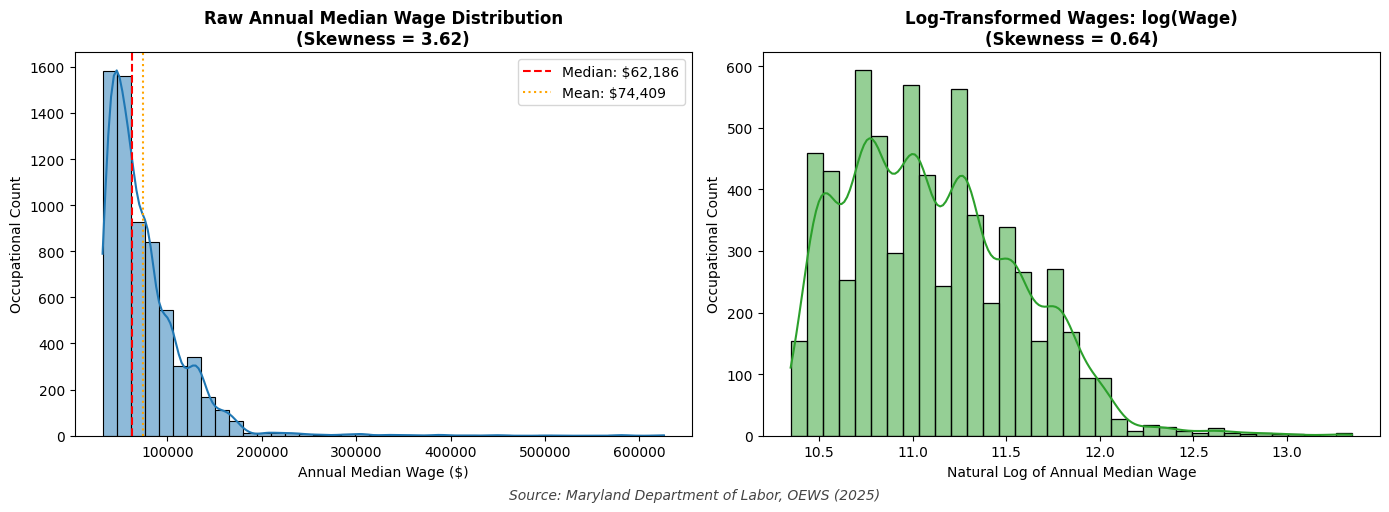

In [52]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Define fig and axes together
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wage distribution
sns.histplot(
    df_detailed["annual_median_wage"],
    kde=True,
    color="#1f77b4",
    bins=40,
    ax=axes[0],
)
axes[0].set_title(
    "Raw Annual Median Wage Distribution\n(Skewness = 3.62)",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Annual Median Wage ($)")
axes[0].set_ylabel("Occupational Count")
axes[0].axvline(
    df_detailed["annual_median_wage"].median(),
    color="red",
    linestyle="--",
    label=f"Median: ${df_detailed['annual_median_wage'].median():,.0f}",
)
axes[0].axvline(
    df_detailed["annual_median_wage"].mean(),
    color="orange",
    linestyle=":",
    label=f"Mean: ${df_detailed['annual_median_wage'].mean():,.0f}",
)
axes[0].legend()



# Log-transformation
log_wages = np.log(df_detailed["annual_median_wage"])
sns.histplot(log_wages, kde=True, color="#2ca02c", bins=35, ax=axes[1])
axes[1].set_title(
    f"Log-Transformed Wages: log(Wage)\n(Skewness = {log_wages.skew():.2f})",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Natural Log of Annual Median Wage")
axes[1].set_ylabel("Occupational Count")

plt.figtext(
    0.5,
    -0.01,
    "Source: Maryland Department of Labor, OEWS (2025)",
    ha="center",
    fontsize=10,
    fontstyle="italic",
    color="#444444",
)


plt.tight_layout()
plt.show()


#### Figure 1: Baseline Wage Distribution and Log Normalization

- Raw Wage Distribution: The raw annual median wages display heavy right-skewness with a skewness score of 3.62, as high-earning specialties elevate the mean of \$74,409 well above the median of \$62,186.
- Log Transformation:  Because standard regression models struggle with lopsided data, applying a natural log transformation normalizes the distribution and reduces skewness to 0.64. This pulls in the extreme high earners and creates a much more balanced bell curve. This confirms that log-transformed wages will give cleaner, more accurate results in the modeling phase.

Analyzed 630 Detailed Occupations
Median Dollar Gap: $17,524.50
IQR (25th - 75th): $9,051.75 - $34,864.25
Median Percentage Spread: 31.40%


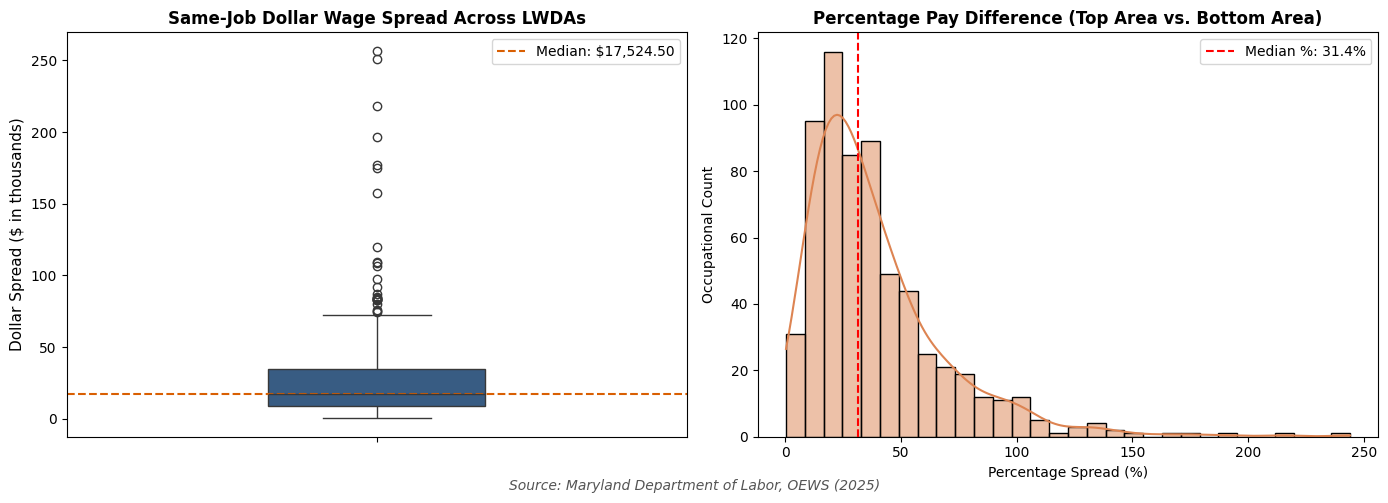

In [53]:
# Filter out statewide 'Maryland' to compare only reporting LWDAs
df_lwdas = df_detailed[df_detailed["area_name"] != "Maryland"].copy()

# Group by 6-digit detailed occupations and calculate max, min, and spread
occ_spread = (
    df_lwdas.groupby(["occupation_code", "occupation_name"])
    .agg(
        areas_reporting=("area_name", "nunique"),
        min_wage=("annual_median_wage", "min"),
        max_wage=("annual_median_wage", "max"),
        mean_median=("annual_median_wage", "mean"),
    )
    .reset_index()
)

# Keep occupations present in at least 2 distinct workforce areas
occ_spread = occ_spread[occ_spread["areas_reporting"] >= 2].copy()
occ_spread["dollar_spread"] = occ_spread["max_wage"] - occ_spread["min_wage"]
occ_spread["pct_spread"] = (
    occ_spread["dollar_spread"] / occ_spread["min_wage"]
) * 100

# Summary metrics
med_gap = occ_spread["dollar_spread"].median()
q25_gap = occ_spread["dollar_spread"].quantile(0.25)
q75_gap = occ_spread["dollar_spread"].quantile(0.75)
print(f"Analyzed {len(occ_spread)} Detailed Occupations")
print(f"Median Dollar Gap: ${med_gap:,.2f}")
print(f"IQR (25th - 75th): ${q25_gap:,.2f} - ${q75_gap:,.2f}")
print(f"Median Percentage Spread: {occ_spread['pct_spread'].median():.2f}%")


# Boxplot of Dollar Spread

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    y=occ_spread["dollar_spread"] / 1000, ax=axes[0], color="#2b5c8f", width=0.35
)
axes[0].set_title(
    "Same-Job Dollar Wage Spread Across LWDAs", fontsize=12, fontweight="bold"
)
axes[0].set_ylabel("Dollar Spread ($ in thousands)", fontsize=11)
axes[0].set_yticks([0, 50, 100, 150, 200, 250])

med_dollar = occ_spread["dollar_spread"].median() / 1000
axes[0].axhline(
    med_dollar,
    color="#d95f02",
    linestyle="--",
    linewidth=1.5,
    label=f"Median: ${med_gap:,.2f}",
)
axes[0].legend(loc="upper right")


# Histogram of Percentage Spread
sns.histplot(
    occ_spread["pct_spread"], kde=True, ax=axes[1], color="#dd8452", bins=30
)
axes[1].set_title(
    "Percentage Pay Difference (Top Area vs. Bottom Area)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Percentage Spread (%)")
axes[1].set_ylabel("Occupational Count")
axes[1].axvline(
    occ_spread["pct_spread"].median(),
    color="red",
    linestyle="--",
    label=f"Median %: {occ_spread['pct_spread'].median():.1f}%",
)
axes[1].legend()

plt.figtext(
    0.5,
    0.01,
    "Source: Maryland Department of Labor, OEWS (2025)",
    ha="center",
    fontsize=10,
    fontstyle="italic",
    color="#555555",
)

plt.tight_layout()
plt.show()

#### Figure 2: Same-Job Dollar Spread and Percentage Pay Difference

To measure how much geography changes pay for the exact same role, I compared the highest- and lowest-paying workforce areas across 630 multi-region occupations in Maryland.

- Dollar Spread Distribution: Across identical job titles, workers in Maryland's highest-paying region earn a median of **\$17,525** more per year than counterparts in the lowest-paying region. High-earning specialties like executives and medical specialists stretch the upper tail past \$250,000, pulling the average gap up to \$25,785.
- Percentage Pay Difference: Getting the same job in the highest-paying region typically means 31.4% more pay than in the lowest-paying region, with most jobs swinging anywhere from 18.8% to 50.1% depending on location.

### EDA 2: LWDA Median Wage and Location Penalty Ranking

In [54]:
# Calculate statewide detailed occupation median wage
statewide_median = df_detailed[df_detailed["area_name"] == "Maryland"][
    "annual_median_wage"
].median()

# Aggregate median wages and demographics across all 13 LWDAs
lwda_summary = (
    df_lwdas_only.groupby("area_name")
    .agg(
        occupation_count=("occupation_code", "count"),
        lwda_median_wage=("annual_median_wage", "median"),
        lwda_mean_wage=("annual_mean_wage", "mean"),
        minority_pct=("minority_pct", "first"),
        total_population=("total_population", "first"),
        is_rural=("is_rural", "first"),
    )
    .reset_index()
)

# Calculate dollar and percentage difference vs. statewide median
lwda_summary["dollar_diff_vs_md"] = (
    lwda_summary["lwda_median_wage"] - statewide_median
)
lwda_summary["pct_diff_vs_md"] = (
    lwda_summary["dollar_diff_vs_md"] / statewide_median
) * 100
lwda_summary = lwda_summary.sort_values(
    "lwda_median_wage", ascending=False
).reset_index(drop=True)

print(f"Statewide Detailed Occupation Median Wage: ${statewide_median:,.2f}\n")
print(
    lwda_summary[[
        "area_name",
        "occupation_count",
        "lwda_median_wage",
        "dollar_diff_vs_md",
        "pct_diff_vs_md",
    ]].to_string(index=False)
)

Statewide Detailed Occupation Median Wage: $63,690.00

             area_name  occupation_count  lwda_median_wage  dollar_diff_vs_md  pct_diff_vs_md
  Prince George's LWDA               529           70666.0             6976.0       10.953054
       Montgomery LWDA               567           69871.0             6181.0        9.704820
   Baltimore City LWDA               548           65773.0             2083.0        3.270529
           Howard LWDA               421           63257.0             -433.0       -0.679856
Southern Maryland LWDA               421           63132.0             -558.0       -0.876119
 Baltimore County LWDA               562           63084.0             -606.0       -0.951484
        Frederick LWDA               413           62743.0             -947.0       -1.486890
     Anne Arundel LWDA               478           62022.5            -1667.5       -2.618150
      Susquehanna LWDA               423           61556.0            -2134.0       -3.350604
     

#### Regional Wage Summary Table

- Above the State Baseline: Only three regions exceed the statewide median, **Prince George's LWDA** (\$70,666.00, +11.0%), **Montgomery LWDA** (\$69,871.00, +9.7%), and **Baltimore City LWDA** (\$65,773.00, +3.3%).
- Below the State Baseline: The remaining ten regions fall below the state average, with rural workforce areas experiencing the steepest location penalties with **Western Maryland LWDA** (\$55,652.00, -12.6%), **Lower Shore LWDA** (\$56,046.50, -12.0%), and **Upper Shore LWDA** (\$56,423.00, -11.4%).

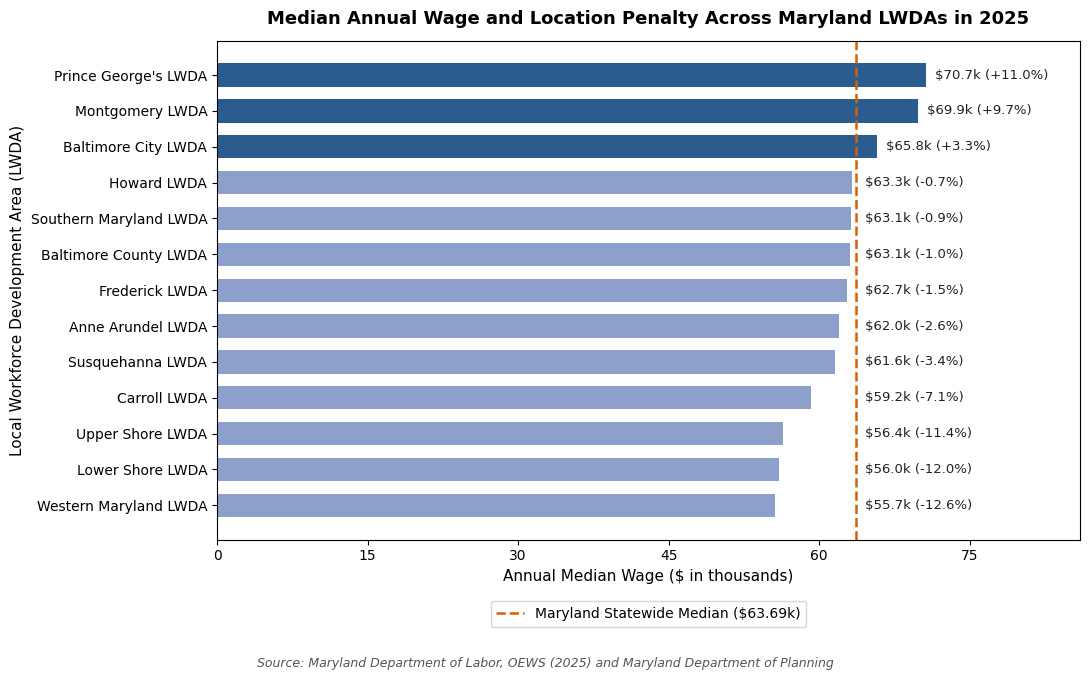

In [55]:
fig, ax = plt.subplots(figsize=(11, 7.0))

# Color-code bars above vs. below the statewide median ($63,690)
colors = [
    '#2b5c8f' if val >= statewide_median else '#8da0cb'
    for val in lwda_summary['lwda_median_wage']
]

bars = ax.barh(
    lwda_summary['area_name'],
    lwda_summary['lwda_median_wage'] / 1000,
    color=colors,
    height=0.65,
)

# Invert y-axis so highest-paying region appears at the top
ax.invert_yaxis()

# Vertical dashed reference line for the Maryland statewide median
ref_x = statewide_median / 1000
ax.axvline(
    ref_x,
    color='#d95f02',
    linestyle='--',
    linewidth=1.8,
    label=f'Maryland Statewide Median (${ref_x:,.2f}k)',
)

# Place all text labels cleanly to the right of both the bar and the dashed line
for bar, pct in zip(bars, lwda_summary['pct_diff_vs_md']):
  width = bar.get_width()
  sign = '+' if pct > 0 else ''
  label_x = max(width, ref_x) + 0.9
  ax.text(
      label_x,
      bar.get_y() + bar.get_height() / 2,
      f'${width:,.1f}k ({sign}{pct:.1f}%)',
      va='center',
      fontsize=9.5,
      color='#222222',
  )

ax.set_title(
    'Median Annual Wage and Location Penalty Across Maryland LWDAs in 2025',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel('Annual Median Wage ($ in thousands)', fontsize=11)
ax.set_ylabel('Local Workforce Development Area (LWDA)', fontsize=11)
ax.set_xticks([0, 15, 30, 45, 60, 75])
ax.set_xlim(0, 86)

# Pull legend box below the x-axis so it never overlaps any bars, text, or lines
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.11),
    frameon=True,
    fontsize=10,
)

# Centered source caption below the legend
plt.figtext(
    0.5,
    0.01,
    'Source: Maryland Department of Labor, OEWS (2025) and Maryland Department of Planning',
    ha='center',
    fontsize=9,
    style='italic',
    color='#555555',
)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])

plt.show()


#### Figure 3: Maryland's Geographic Wage Divide

- Metro vs. Rural Split: Visualizing the rankings shows that positive wage premiums are concentrated inside the Washington–Baltimore core, while central suburbs cluster just below the statewide dashed line and rural Eastern Shore and Western regions drop sharply to the left.
- Wide Top-to-Bottom Spread: Comparing the longest and shortest bars reveals a $15,000 median pay gap separating Maryland's highest- and lowest-paying workforce areas. This highlights how much geography impacts a worker's paycheck, even before factoring in the mix of industries in each area.

### EDA 3: Industry Sector Pay Gaps Across Regions

Now it is established that where a worker lives heavily shapes their paycheck, the next step is seeing how much **industry mix** drives those regional gaps. To test whether certain career fields pay consistently better, or see wider pay gaps across Maryland, I grouped all detailed jobs into their 22 major occupational sectors and compared median wages across the 13 workforce areas.

In [56]:
# 2-digit SOC major group code and map to standard titles (comes from US Bureau of Labor Statistics).
# I used Gemini to compute the mappings to help save time on the analysis.
soc_names = {
    '11': 'Management',
    '13': 'Business and Financial Operations',
    '15': 'Computer and Mathematical',
    '17': 'Architecture and Engineering',
    '19': 'Life, Physical and Social Science',
    '21': 'Community and Social Service',
    '23': 'Legal',
    '25': 'Educational Instruction and Library',
    '27': 'Arts, Design, Entertainment and Media',
    '29': 'Healthcare Practitioners and Technical',
    '31': 'Healthcare Support',
    '33': 'Protective Service',
    '35': 'Food Preparation and Serving',
    '37': 'Building & Grounds Cleaning/Maint.',
    '39': 'Personal Care and Service',
    '41': 'Sales and Related',
    '43': 'Office and Administrative Support',
    '45': 'Farming, Fishing and Forestry',
    '47': 'Construction and Extraction',
    '49': 'Installation, Maintenance and Repair',
    '51': 'Production',
    '53': 'Transportation and Material Moving',
}

df_lwdas_only['soc_major'] = df_lwdas_only['occupation_code'].str[:2]
df_lwdas_only['sector_name'] = df_lwdas_only['soc_major'].map(soc_names)

# Compute each LWDA's median wage per sector, then summarize across regions
lwda_sector_medians = (
    df_lwdas_only.groupby(['sector_name', 'area_name'])['annual_median_wage']
    .median()
    .reset_index()
)

sector_summary = (
    lwda_sector_medians.groupby('sector_name')
    .agg(
        lwda_count=('area_name', 'count'),
        state_sector_median=('annual_median_wage', 'median'),
        lowest_lwda_median=('annual_median_wage', 'min'),
        highest_lwda_median=('annual_median_wage', 'max'),
    )
    .reset_index()
)

sector_summary['regional_dollar_gap'] = (
    sector_summary['highest_lwda_median'] - sector_summary['lowest_lwda_median']
)
sector_summary['regional_pct_gap'] = (
    sector_summary['regional_dollar_gap']
    / sector_summary['lowest_lwda_median']
) * 100

sector_summary = sector_summary.sort_values(
    'state_sector_median', ascending=False
).reset_index(drop=True)

print(sector_summary.round(1).to_string(index=False))

                           sector_name  lwda_count  state_sector_median  lowest_lwda_median  highest_lwda_median  regional_dollar_gap  regional_pct_gap
             Computer and Mathematical          13             126981.0             81033.0             132621.0              51588.0              63.7
                            Management          13             125704.0            110681.5             139490.0              28808.5              26.0
          Architecture and Engineering          13              97519.5             80497.0             124772.0              44275.0              55.0
Healthcare Practitioners and Technical          13              93600.0             78794.0             102657.0              23863.0              30.3
     Life, Physical and Social Science          13              90201.5             76056.0             126214.5              50158.5              65.9
                                 Legal          13              84157.0             7107

#### Career Sector Wage Summary

- **Computer and Mathematical** (\$126,981) and **Management** (\$125,704) lead the state, paying more than triple lower earning sectors such as **Food Preparation and Serving** (\$36,305) and **Personal Care and Service** (\$36,935).
- Knowledge-based fields vary dramatically by location. **Legal** wages jump **116.9%** (+$83,061) between Maryland's lowest- and highest-paying regions, followed by **Life, Physical and Social Science** (+65.9%) and **Computer and Mathematical** (+63.7%).
- Support and service roles pay nearly the same everywhere, with **Healthcare Support** (+8.8%) and **Food Preparation and Serving** (+10.4%) showing minimal regional variation.

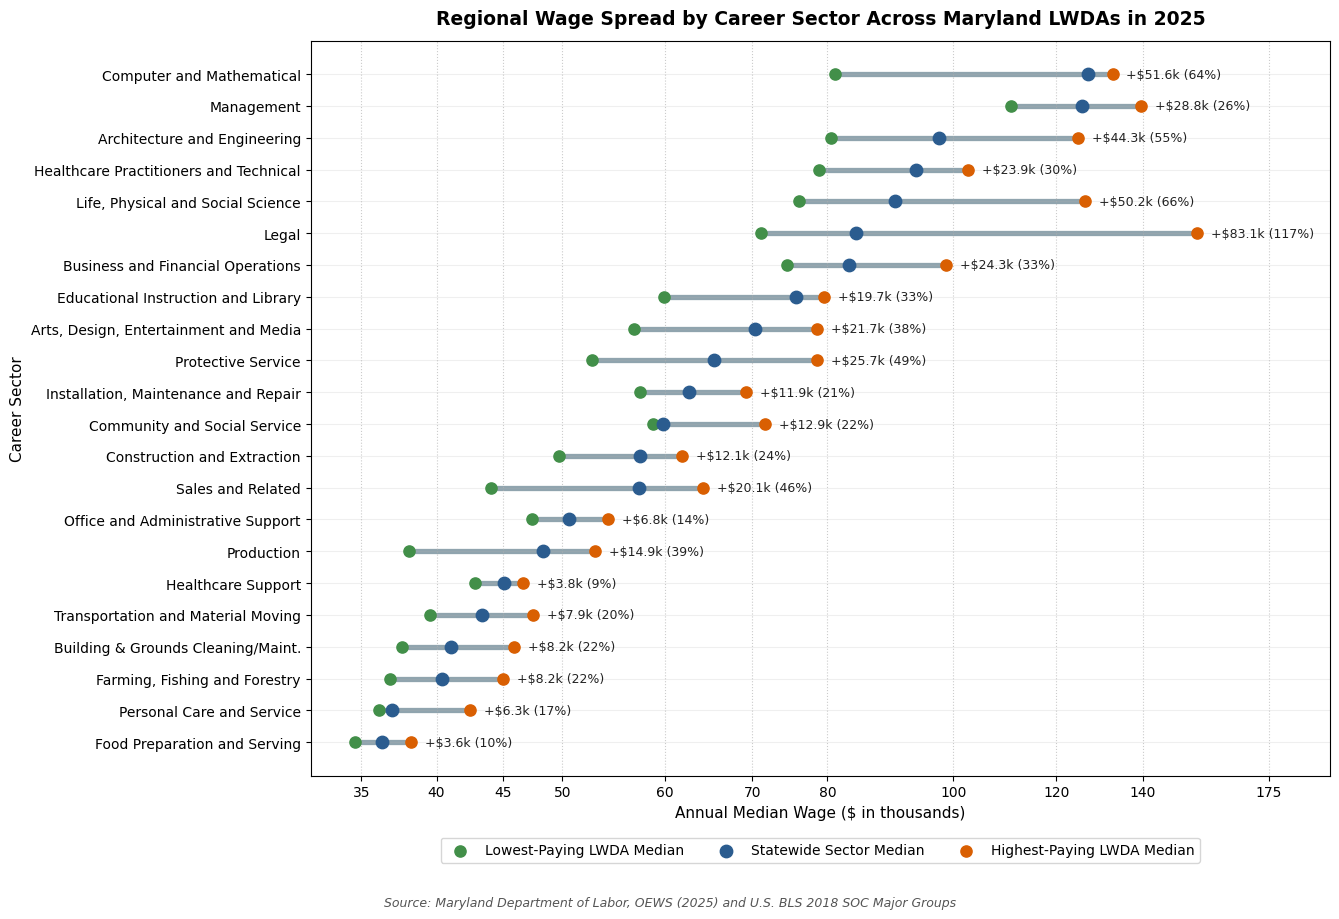

In [57]:
# Sort sectors by statewide sector median so highest-paying appears at top
plot_df = sector_summary.sort_values(
    'state_sector_median', ascending=True
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13.5, 9.5))
y_pos = range(len(plot_df))

# Horizontal range bars connecting lowest LWDA median to highest LWDA median
ax.hlines(
    y=y_pos,
    xmin=plot_df['lowest_lwda_median'] / 1000,
    xmax=plot_df['highest_lwda_median'] / 1000,
    color='#90a4ae',
    linewidth=3.8,
    zorder=1,
)

# Scatter points for Lowest LWDA, Statewide Sector Median, and Highest LWDA
ax.scatter(
    plot_df['lowest_lwda_median'] / 1000,
    y_pos,
    color='#428F49',
    s=65,
    label='Lowest-Paying LWDA Median',
    zorder=2,
)
ax.scatter(
    plot_df['state_sector_median'] / 1000,
    y_pos,
    color='#2b5c8f',
    s=80,
    label='Statewide Sector Median',
    zorder=3,
)
ax.scatter(
    plot_df['highest_lwda_median'] / 1000,
    y_pos,
    color='#d95f02',
    s=65,
    label='Highest-Paying LWDA Median',
    zorder=2,
)

# Log-scale x-axis stretches out lower-paying sectors so small dollar gaps are clearly visible
ax.set_xscale('log')

# Direct dollar and percentage gap labels to the right of each bar
for idx, row in plot_df.iterrows():
  max_x = row['highest_lwda_median'] / 1000
  gap_k = row['regional_dollar_gap'] / 1000
  ax.text(
      max_x * 1.025,
      idx,
      f"+${gap_k:.1f}k ({row['regional_pct_gap']:.0f}%)",
      va='center',
      fontsize=9,
      color='#222222',
  )

ax.set_yticks(list(y_pos))
ax.set_yticklabels(plot_df['sector_name'], fontsize=10)
ax.set_xlabel('Annual Median Wage ($ in thousands)', fontsize=11)

ax.set_yticks(list(y_pos))
ax.set_yticklabels(plot_df['sector_name'], fontsize=10)
ax.set_ylabel('Career Sector', fontsize=11)

# Clean custom ticks
custom_ticks = [35, 40, 45, 50, 60, 70, 80, 100, 120, 140, 175]
ax.set_xticks(custom_ticks)
ax.set_xticklabels([str(t) for t in custom_ticks])
ax.minorticks_off()
ax.set_xlim(32, 195)

ax.grid(axis='x', linestyle=':', alpha=0.65)
ax.grid(axis='y', linestyle='-', alpha=0.2)

ax.set_title(
    'Regional Wage Spread by Career Sector Across Maryland LWDAs in 2025',
    fontsize=13.5,
    fontweight='bold',
    pad=12,
)

# Legend cleanly below the x-axis label
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.075),
    ncol=3,
    frameon=True,
    fontsize=10,
)

# Centered source caption below the legend
plt.figtext(
    0.5,
    0.01,
    'Source: Maryland Department of Labor, OEWS (2025) and U.S. BLS 2018 SOC Major Groups',
    ha='center',
    fontsize=9,
    style='italic',
    color='#555555',
)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

#### Figure 4: How Industry Mix Widens Regional Pay Gaps

- Top-Paying Sectors Stretch Across Regions: The dumbbell bars widen dramatically toward the top of the chart. Fields like **Legal** (+\$83.1k / 117%), **Life, Physical and Social Science** (+\$50.2k / 66%), and **Computer and Mathematical** (+\$51.6k / 64%) see massive location pay advantage in metro hubs, whereas lower-paying service and support lines stay tightly compressed.
- Skewed Regional Benchmarks: For several specialized fields (like Computer and Mathematical and Educational Instruction), the blue statewide median dot sits right next to the orange top-paying dot. This reveals that a handful of high-paying regions pull the state baseline up, while rural areas trail far behind.

### EDA 4: Demographics, Rural Status and Wage Penalties

After seeing how location and career sector shape pay across Maryland, the next step is testing whether regional demographics and rural status explain why certain workforce areas pay more than others. To evaluate this, I compared each LWDA's minority population share (`minority_pct`) and rural classification (`is_rural`) against its regional median wage and percentage gap relative to the statewide baseline.

In [58]:
from scipy.stats import pearsonr, ttest_ind

# Inspect available demographic/regional columns in df_lwdas_only
print(
    'Available columns:',
    [
        c
        for c in df_lwdas_only.columns
        if any(
            k in c
            for k in [
                'rural',
                'minority',
                'pop',
                'black',
                'white',
                'hispanic',
                'asian',
                'race',
            ]
        )
    ],
)

# 2. Aggregate at the LWDA level (13 rows)
# Adjust column names below if your merged demographic columns use slightly different names
demo_cols = [
    c
    for c in df_lwdas_only.columns
    if c in ['minority_pct', 'is_rural', 'total_population']
]

lwda_demo = (
    df_lwdas_only.groupby('area_name', as_index=False)
    .agg(
        lwda_median_wage=('annual_median_wage', 'median'),
        **{col: (col, 'first') for col in demo_cols},
    )
    .sort_values('lwda_median_wage', ascending=False)
    .reset_index(drop=True)
)

lwda_demo['pct_diff_vs_md'] = (
    (lwda_demo['lwda_median_wage'] - statewide_median) / statewide_median
) * 100

print('\n--- LWDA Demographic & Wage Summary ---')
print(lwda_demo.round(2).to_string(index=False))

# 3. Correlation & rural vs. non-rural comparison (if columns are present)
if 'minority_pct' in lwda_demo.columns:
  r_val, p_val = pearsonr(
      lwda_demo['minority_pct'], lwda_demo['pct_diff_vs_md']
  )
  print(
      '\nCorrelation (Minority Share vs. % Wage Difference): r ='
      f' {r_val:.3f}, p = {p_val:.4f}'
  )

if 'is_rural' in lwda_demo.columns:
  rural_group = lwda_demo[lwda_demo['is_rural'] == True]['lwda_median_wage']
  urban_group = lwda_demo[lwda_demo['is_rural'] == False]['lwda_median_wage']
  t_stat, t_pval = ttest_ind(urban_group, rural_group, equal_var=False)
  print(
      f'Non-Rural Median Wage: ${urban_group.median():,.2f} (n ='
      f' {len(urban_group)})'
  )
  print(
      f'Rural Median Wage:     ${rural_group.median():,.2f} (n ='
      f' {len(rural_group)})'
  )
  print(
      f"Difference:            ${urban_group.median() - rural_group.median():,.2f}"
      f' (t = {t_stat:.2f}, p = {t_pval:.4f})'
  )

Available columns: ['total_population', 'minority_population', 'minority_pct', 'is_rural']

--- LWDA Demographic & Wage Summary ---
             area_name  lwda_median_wage  total_population  minority_pct  is_rural  pct_diff_vs_md
  Prince George's LWDA           70666.0            970374         89.42         0           10.95
       Montgomery LWDA           69871.0           1074582         60.98         0            9.70
   Baltimore City LWDA           65773.0            569997         73.70         0            3.27
           Howard LWDA           63257.0            339183         55.96         0           -0.68
Southern Maryland LWDA           63132.0            387769         48.62         1           -0.88
 Baltimore County LWDA           63084.0            847650         51.07         0           -0.95
        Frederick LWDA           62743.0            302883         37.81         0           -1.49
     Anne Arundel LWDA           62022.5            603380         40.78    

#### Regional Demographics and Rural Status Summary Table

- Minority population share strongly correlates with regional wage gains (**r = 0.846, p = 0.0003**), led by diverse metro hubs like **Prince George's** (89.4%, +11.0%) and **Montgomery** (61.0%, +9.7%).
- Non-rural regions (\$63,084 median) outearn rural areas (\$56,235 median) by **\$6,849 per year** (Welch's t = 2.93, p = 0.0250), with all four rural LWDAs falling below the statewide baseline.

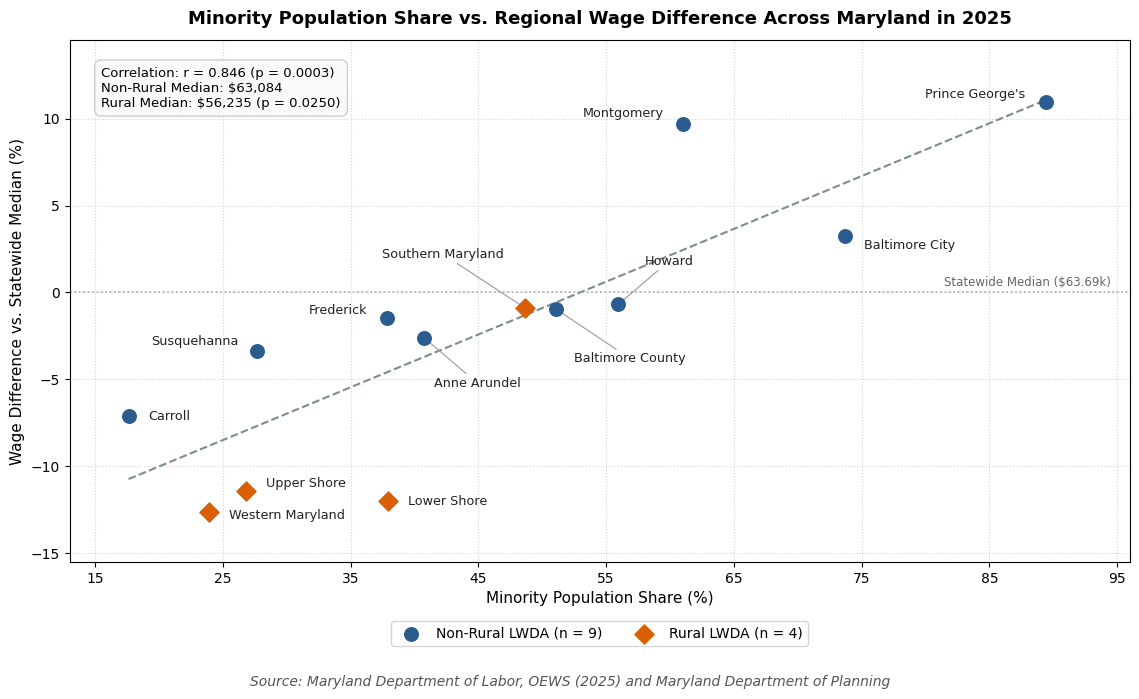

In [59]:
fig, ax = plt.subplots(figsize=(11.5, 7.2))

# 1. Clean trendline without the wide gray confidence ribbon
sns.regplot(
    data=lwda_demo,
    x='minority_pct',
    y='pct_diff_vs_md',
    scatter=False,
    ci=None,
    ax=ax,
    color='#7f8c8d',
    line_kws={
        'linestyle': '--',
        'linewidth': 1.5,
        'label': 'Linear Trend (r = 0.846)',
    },
)

# 2. Horizontal reference line at 0% (Statewide Median Baseline)
ax.axhline(0, color='#aaaaaa', linestyle=':', linewidth=1.2)
ax.text(
    94.5,
    0.4,
    'Statewide Median ($63.69k)',
    fontsize=8.5,
    color='#666666',
    ha='right',
)

# 3. Scatter points split by Rural vs. Non-Rural status
non_rural = lwda_demo[lwda_demo['is_rural'] == 0]
rural = lwda_demo[lwda_demo['is_rural'] == 1]

ax.scatter(
    non_rural['minority_pct'],
    non_rural['pct_diff_vs_md'],
    color='#2b5c8f',
    s=95,
    label='Non-Rural LWDA (n = 9)',
    zorder=4,
)
ax.scatter(
    rural['minority_pct'],
    rural['pct_diff_vs_md'],
    color='#d95f02',
    s=95,
    marker='D',
    label='Rural LWDA (n = 4)',
    zorder=4,
)

# 4. Carefully spaced labels + subtle leader lines for the tight center cluster
label_positions = {
    "Prince George's LWDA": (87.8, 11.4, 'right', False),
    'Montgomery LWDA': (59.5, 10.3, 'right', False),
    'Baltimore City LWDA': (75.2, 2.7, 'left', False),
    'Howard LWDA': (58.0, 1.8, 'left', True),
    'Baltimore County LWDA': (52.5, -3.8, 'left', True),
    'Southern Maryland LWDA': (47.0, 2.2, 'right', True),
    'Anne Arundel LWDA': (41.5, -5.2, 'left', True),
    'Frederick LWDA': (36.3, -1.0, 'right', False),
    'Susquehanna LWDA': (26.2, -2.8, 'right', False),
    'Carroll LWDA': (19.2, -7.1, 'left', False),
    'Upper Shore LWDA': (28.4, -11.0, 'left', False),
    'Lower Shore LWDA': (39.5, -12.0, 'left', False),
    'Western Maryland LWDA': (25.5, -12.8, 'left', False),
}

for _, row in lwda_demo.iterrows():
  name = row['area_name']
  short_name = name.replace(' LWDA', '')
  tx, ty, ha, use_arrow = label_positions[name]
  if use_arrow:
    ax.annotate(
        short_name,
        xy=(row['minority_pct'], row['pct_diff_vs_md']),
        xytext=(tx, ty),
        fontsize=9.2,
        ha=ha,
        va='center',
        color='#222222',
        arrowprops=dict(
            arrowstyle='-', color='#999999', lw=0.8, shrinkA=0, shrinkB=4
        ),
    )
  else:
    ax.text(
        tx, ty, short_name, fontsize=9.2, ha=ha, va='center', color='#222222'
    )

# 5. Clean stats box (avoids paired $ signs that trigger Matplotlib math italics)
stats_text = (
    'Correlation: r = 0.846 (p = 0.0003)\n'
    'Non-Rural Median: $63,084\n'
    'Rural Median: $56,235 (p = 0.0250)'
)
ax.text(
    0.03,
    0.95,
    stats_text,
    transform=ax.transAxes,
    fontsize=9.5,
    va='top',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='#f8f9fa',
        edgecolor='#cccccc',
        alpha=0.95,
    ),
)

ax.set_title(
    'Minority Population Share vs. Regional Wage Difference Across Maryland in 2025',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel('Minority Population Share (%)', fontsize=11)
ax.set_ylabel('Wage Difference vs. Statewide Median (%)', fontsize=11)

ax.set_xticks([15, 25, 35, 45, 55, 65, 75, 85, 95])
ax.set_yticks([-15, -10, -5, 0, 5, 10, 15])
ax.set_xlim(13, 96)
ax.set_ylim(-15.5, 14.5)
ax.grid(True, linestyle=':', alpha=0.55)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.10),
    ncol=3,
    frameon=True,
    fontsize=10,
)

plt.figtext(
    0.5,
    0.01,
    'Source: Maryland Department of Labor, OEWS (2025) and Maryland Department of Planning',
    ha='center',
    fontsize=10,
    style='italic',
    color='#555555',
)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

#### Figure 5: Urbanization Drives the Diversity Wage Pattern

- Strong Upward Trend Driven by Metro Hubs: The upward slope (**r = 0.846**) reflects Maryland's economic geography. Its most racially diverse jurisdictions (**Prince George's**, **Montgomery**, and **Baltimore City**) sit inside the Washington-Baltimore job core, while less diverse regions cluster in lower-paying outlying counties.
- Rural Regions Cluster at the Bottom: All four orange rural diamonds fall below the zero-percent statewide baseline, with **Western Maryland**, **Upper Shore**, and **Lower Shore** forming a distinct lower-wage cluster in the bottom-left corner.

### EDA 5: Internal Wage Inequality (90th vs. 10th Percentile)

While the earlier sections compared typical (median) pay across regions and sectors, high-paying metro hubs often see much wider gaps between lowest earning workers and top earners. To measure internal wage inequality within each workforce area, I calculated the **90/10 wage ratio** (`annual_90th_percentile / annual_10th_percentile`) across all detailed occupations and compared how sharply top earners pull away from lowest earners workers in non-rural versus rural LWDAs.

In [60]:
from scipy.stats import ttest_ind

# 1. Calculate job-level 90/10 ratio and dollar gap across detailed LWDA records
df_ineq = df_lwdas_only.dropna(
    subset=['annual_10th_percentile', 'annual_90th_percentile']
).copy()
df_ineq['wage_ratio_90_10'] = (
    df_ineq['annual_90th_percentile'] / df_ineq['annual_10th_percentile']
)
df_ineq['wage_gap_90_10'] = (
    df_ineq['annual_90th_percentile'] - df_ineq['annual_10th_percentile']
)

# 2. Aggregate by LWDA (13 rows)
lwda_ineq = (
    df_ineq.groupby(['area_name', 'is_rural'], as_index=False)
    .agg(
        median_10th_pct=('annual_10th_percentile', 'median'),
        median_90th_pct=('annual_90th_percentile', 'median'),
        median_90_10_gap=('wage_gap_90_10', 'median'),
        median_90_10_ratio=('wage_ratio_90_10', 'median'),
    )
    .sort_values('median_90_10_ratio', ascending=False)
    .reset_index(drop=True)
)

print('Regional 90th vs. 10th Percentile Wage Inequality Summary')
print(lwda_ineq.round(2).to_string(index=False))

# 3. Compare Non-Rural vs. Rural 90/10 wage ratios
non_rural_ratio = lwda_ineq[lwda_ineq['is_rural'] == 0]['median_90_10_ratio']
rural_ratio = lwda_ineq[lwda_ineq['is_rural'] == 1]['median_90_10_ratio']
t_stat, p_val = ttest_ind(non_rural_ratio, rural_ratio, equal_var=False)

print(
    f'\nNon-Rural Median 90/10 Ratio: {non_rural_ratio.median():.2f}x (n ='
    f' {len(non_rural_ratio)})'
)
print(
    f'Rural Median 90/10 Ratio:     {rural_ratio.median():.2f}x (n ='
    f' {len(rural_ratio)})'
)
print(f'Two-Sample t-test: t = {t_stat:.2f}, p = {p_val:.4f}')

Regional 90th vs. 10th Percentile Wage Inequality Summary
             area_name  is_rural  median_10th_pct  median_90th_pct  median_90_10_gap  median_90_10_ratio
           Howard LWDA         0          44306.0          98948.0           51786.0                2.09
   Baltimore City LWDA         0          45482.0          99313.0           51141.0                2.09
 Baltimore County LWDA         0          43835.5          97592.5           48888.0                2.08
     Anne Arundel LWDA         0          43392.0          98520.5           50965.0                2.08
      Susquehanna LWDA         0          42390.0          95532.0           49244.0                2.08
       Montgomery LWDA         0          47326.0         105100.0           56731.0                2.08
Southern Maryland LWDA         1          44497.0         100213.0           49246.0                2.07
        Frederick LWDA         0          45201.0          97893.0           49146.0                2.

#### Regional 90th vs. 10th Percentile Summary Table

- Top earners (90th percentile) make roughly **2.0x** what lower earning workers (10th percentile) earn across every Maryland region. It ranges narrowly from **1.99x** in **Western Maryland** to **2.09x** in **Howard** and **Baltimore City**, with no statistically significant gap between non-rural (2.08x) and rural (2.03x) areas (**t = 2.27, p = 0.0932**).
- Even though the ratio is steady, higher baseline pay means the actual dollar gap between top and lower earners reaches **\$56,731** in **Montgomery** and **\$56,392** in **Prince George's**, compared to **\$40,250** in **Western Maryland**.

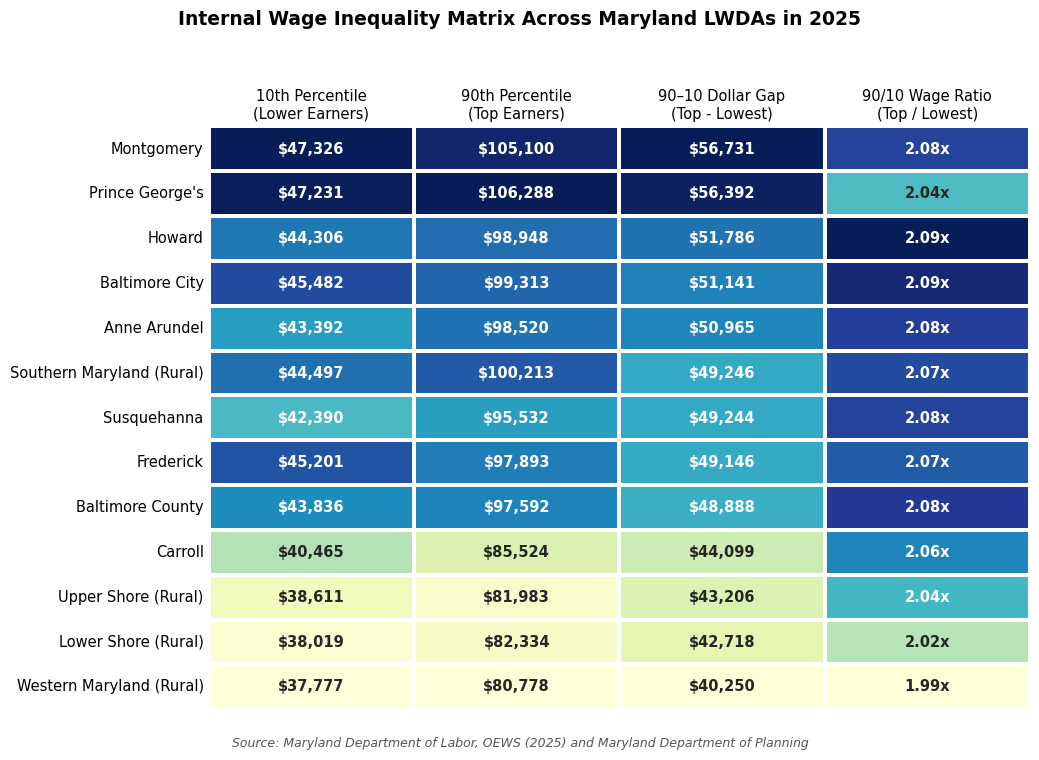

In [62]:
# Sort by median 90-10 dollar gap descending and tag rural regions clearly
heat_df = lwda_ineq.sort_values('median_90_10_gap', ascending=False).copy()
heat_df['Region'] = heat_df.apply(
    lambda r: (
        f"{r['area_name'].replace(' LWDA', '')} (Rural)"
        if r['is_rural'] == 1
        else r['area_name'].replace(' LWDA', '')
    ),
    axis=1,
)

# Normalize each column 0-1 for color shading while displaying exact raw values inside each cell
cols = [
    'median_10th_pct',
    'median_90th_pct',
    'median_90_10_gap',
    'median_90_10_ratio',
]
col_labels = [
    '10th Percentile\n(Lower Earners)',
    '90th Percentile\n(Top Earners)',
    '90–10 Dollar Gap\n(Top - Lowest)',
    '90/10 Wage Ratio\n(Top / Lowest)',
]

norm_matrix = pd.DataFrame(index=heat_df['Region'])
annot_matrix = pd.DataFrame(index=heat_df['Region'], dtype=str)

for c, lbl in zip(cols, col_labels):
  vals = heat_df[c].values
  norm_matrix[lbl] = (vals - vals.min()) / (vals.max() - vals.min())
  if c == 'median_90_10_ratio':
    annot_matrix[lbl] = [f'{v:.2f}x' for v in vals]
  else:
    annot_matrix[lbl] = [f'${v:,.0f}' for v in vals]

fig, ax = plt.subplots(figsize=(10.5, 7.6))

sns.heatmap(
    norm_matrix,
    annot=annot_matrix,
    fmt='',
    cmap='YlGnBu',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 10.5, 'weight': 'bold'},
    ax=ax,
)

ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
ax.tick_params(axis='x', length=0, labelsize=10.5)
ax.tick_params(axis='y', length=0, labelsize=10.5, rotation=0)
ax.set_ylabel('')

fig.suptitle(
    'Internal Wage Inequality Matrix Across Maryland LWDAs in 2025',
    fontsize=13.5,
    fontweight='bold',
    y=0.98,
)

plt.figtext(
    0.5,
    0.01,
    'Source: Maryland Department of Labor, OEWS (2025) and Maryland Department of Planning',
    ha='center',
    fontsize=9,
    style='italic',
    color='#555555',
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.show()

#### Figure 6: How Internal Pay Inequality Scales Across Regions

- Metro Hubs Show Darkest Shading Across Dollar Columns: **Montgomery** and **Prince George's** sit at the top with the darkest shading across lowest earning pay (\$47.2k–\$47.3k), top-earner pay (\$105.1k–\$106.3k), and total 90–10 dollar spread (\$56.4k–\$56.7k), whereas rural regions like **Western Maryland**, **Lower Shore**, and **Upper Shore** cluster at the bottom in pale yellow.
- Ratios Stay Uniform Even When Dollar Gaps Widen: Looking down the far-right column, the 90/10 wage ratio remains nearly constant in dark blue across almost every suburban and urban region (**2.07x–2.09x**), showing that larger dollar gaps in metro hubs reflect higher pay levels overall, not a wider gap in percentage terms.